## I. Notebook 1: Análise Demográfica e PCA

Este *notebook* foca na **Preparação e Redução de Dimensionalidade** dos dados das Unidades Federativas (UFs) brasileiras usando a **Análise de Componentes Principais (PCA)**.

**Objetivo:** Reduzir um conjunto de características demográficas (variáveis numéricas) para duas dimensões principais, permitindo uma visualização em 2D de como as Unidades Federativas (UFs) ou Municípios se agrupam, baseando-se em seus perfis populacionais.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [11]:
df_uf = pd.read_csv('../data/censo2022/dados_demograficos_uf.csv')
df_municipios = pd.read_excel('../data/censo2022/br_ibge_censo_2022_municipio.xlsx')
df_alfabetizacao = pd.read_excel('../data/censo2022/br_ibge_censo_2022_alfabetizacao_grupo_idade_sexo_raca.xlsx')

In [12]:
df_municipios_uf = df_municipios.groupby('sigla_uf').agg({
    'populacao': 'sum',
    'domicilios': 'sum',
    'area': 'sum',
    'taxa_alfabetizacao': 'mean',
    'razao_sexo': 'mean',
    'populacao_indigena': 'sum',
    'populacao_quilombola': 'sum'
}).reset_index()

# Calcular densidade demográfica
df_municipios_uf['densidade_demografica'] = df_municipios_uf['populacao'] / df_municipios_uf['area']

# Mesclar todos os dados por UF
df_completo = pd.merge(df_uf, df_municipios_uf, on='sigla_uf', how='inner')

In [13]:
# Selecionar apenas colunas numéricas para PCA
colunas_numericas = [
    'idade_mediana', 'indice_envelhecimento', 'populacao', 
    'domicilios', 'area', 'taxa_alfabetizacao', 'razao_sexo',
    'populacao_indigena', 'populacao_quilombola', 'densidade_demografica'
]

# Verificar e tratar valores NaN
print("Valores NaN por coluna:")
print(df_completo[colunas_numericas].isna().sum())

# Preencher NaN com a média da coluna
df_completo[colunas_numericas] = df_completo[colunas_numericas].fillna(
    df_completo[colunas_numericas].mean()
)

# Criar matriz X
X = df_completo[colunas_numericas].values

# 3. PADRONIZAÇÃO DOS DADOS
X_padronizado = X - np.mean(X, axis=0)

# 4. CÁLCULO DA PCA COM NUMPY
# Matriz de covariância
matriz_covariancia = np.cov(X_padronizado.T)
print(f"Dimensões da matriz de covariância: {matriz_covariancia.shape}")

# Autovalores e autovetores
autovalores, autovetores = np.linalg.eig(matriz_covariancia)

# Ordenar autovalores e autovetores em ordem decrescente
indices_ordenados = np.argsort(autovalores)[::-1]
autovalores_ordenados = autovalores[indices_ordenados]
autovetores_ordenados = autovetores[:, indices_ordenados]

# print(f"Autovalores ordenados: {autovalores_ordenados}")

# Variância
variancia_explicada = autovalores_ordenados / np.sum(autovalores_ordenados)
#print(f"Variância explicada pelos 2 primeiros componentes: {variancia_explicada[:2]}")
#print(f"Variância total explicada: {np.sum(variancia_explicada[:2]):.2%}")

# Selecionar K=2 componentes principais
componentes_principais = autovetores_ordenados[:, :2]

# 5. PROJEÇÃO DOS DADOS
X_projetado = np.dot(X_padronizado, componentes_principais)

# Adicionar componentes ao DataFrame
df_completo['PC1'] = X_projetado[:, 0]
df_completo['PC2'] = X_projetado[:, 1]

Valores NaN por coluna:
idade_mediana            0
indice_envelhecimento    0
populacao                0
domicilios               0
area                     0
taxa_alfabetizacao       0
razao_sexo               0
populacao_indigena       0
populacao_quilombola     0
densidade_demografica    0
dtype: int64
Dimensões da matriz de covariância: (10, 10)


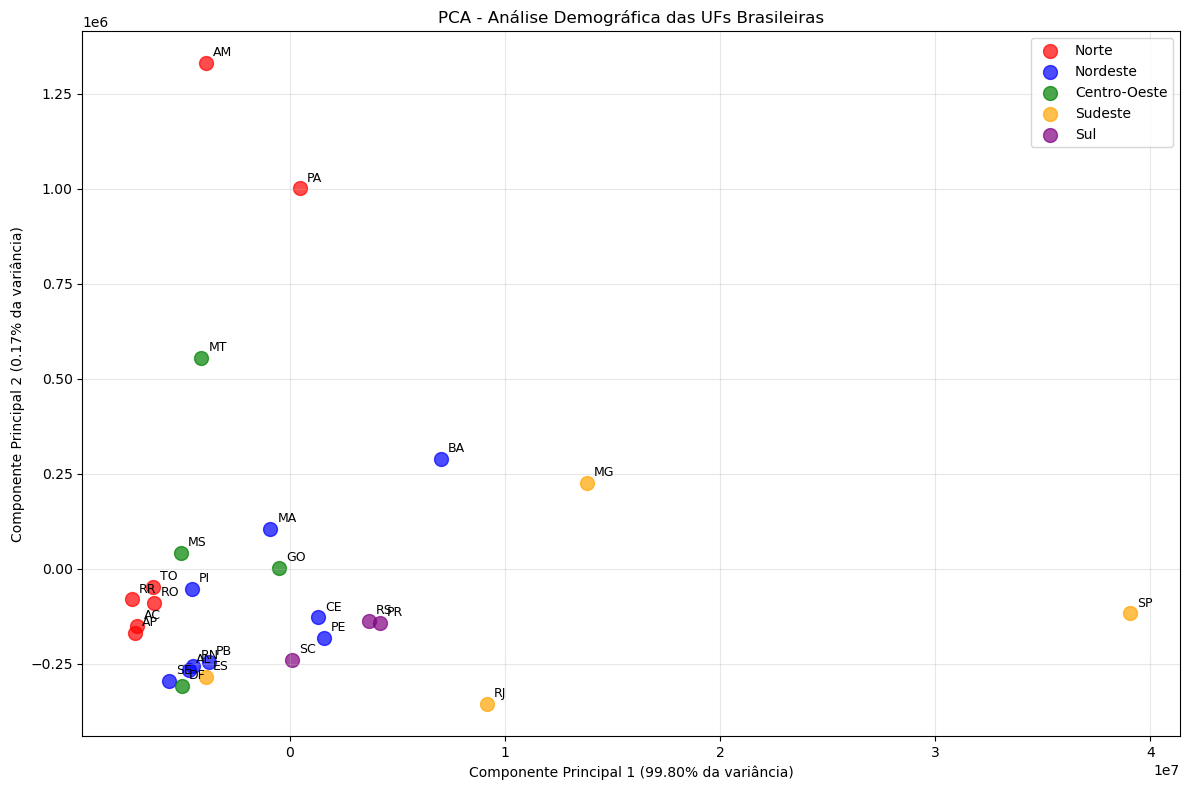

In [14]:
plt.figure(figsize=(12, 8))

# Mapa de cores por região
regioes = {
    'Norte': ['AC', 'AM', 'AP', 'PA', 'RO', 'RR', 'TO'],
    'Nordeste': ['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE'],
    'Centro-Oeste': ['DF', 'GO', 'MT', 'MS'],
    'Sudeste': ['ES', 'MG', 'RJ', 'SP'],
    'Sul': ['PR', 'RS', 'SC']
}

df_completo['regiao'] = df_completo['sigla_uf'].apply(
    lambda uf: next((regiao for regiao, ufs in regioes.items() if uf in ufs), 'Outro')
)

cores_regioes = {
    'Norte': 'red',
    'Nordeste': 'blue', 
    'Centro-Oeste': 'green',
    'Sudeste': 'orange',
    'Sul': 'purple'
}

for regiao, cor in cores_regioes.items():
    mask = df_completo['regiao'] == regiao
    plt.scatter(
        df_completo.loc[mask, 'PC1'], 
        df_completo.loc[mask, 'PC2'],
        c=cor, label=regiao, alpha=0.7, s=100
    )

for i, row in df_completo.iterrows():
    plt.annotate(row['sigla_uf'], (row['PC1'], row['PC2']), 
                xytext=(5, 5), textcoords='offset points', fontsize=9)

plt.xlabel(f'Componente Principal 1 ({variancia_explicada[0]:.2%} da variância)')
plt.ylabel(f'Componente Principal 2 ({variancia_explicada[1]:.2%} da variância)')
plt.title('PCA - Análise Demográfica das UFs Brasileiras')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig('../resultados/pca_ufs_brasileiras.png', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
# Verificar se todas as colunas existem no DataFrame
colunas_disponiveis = [col for col in colunas_numericas if col in df_completo.columns]
print(f"Colunas numéricas disponíveis: {colunas_disponiveis}")

Colunas numéricas disponíveis: ['idade_mediana', 'indice_envelhecimento', 'populacao', 'domicilios', 'area', 'taxa_alfabetizacao', 'razao_sexo', 'populacao_indigena', 'populacao_quilombola', 'densidade_demografica']


In [16]:
# ANÁLISE DOS COMPONENTES

# Mostrar carga das variáveis nos componentes
cargas_componentes = pd.DataFrame({
    'Variável': colunas_disponiveis,
    'PC1': componentes_principais[:, 0],
    'PC2': componentes_principais[:, 1]
})

print("\nCargas das variáveis nos componentes principais (ordenado por PC1):")
cargas_ordenadas = cargas_componentes.sort_values('PC1', key=abs, ascending=False)
print(cargas_ordenadas)

# Identificar UFs com perfis extremos
print("\nUFs com maiores valores no PC1 (perfil característico):")
print(df_completo.nlargest(3, 'PC1')[['sigla_uf', 'PC1', 'regiao']])

print("\nUFs com menores valores no PC1 (perfil oposto):")
print(df_completo.nsmallest(3, 'PC1')[['sigla_uf', 'PC1', 'regiao']])


Cargas das variáveis nos componentes principais (ordenado por PC1):
                Variável           PC1           PC2
2              populacao  9.374183e-01  8.717163e-02
3             domicilios  3.481965e-01 -2.395909e-01
8   populacao_quilombola  1.868609e-03  6.198041e-02
4                   area  1.647069e-03  9.468261e-01
7     populacao_indigena  1.778063e-04  1.862149e-01
9  densidade_demografica  2.961739e-06 -1.107434e-04
1  indice_envelhecimento  1.202995e-06 -1.970588e-05
0          idade_mediana  2.290242e-07 -4.658469e-06
6             razao_sexo -9.165977e-08  5.750817e-06
5     taxa_alfabetizacao  2.098244e-09  3.506570e-09

UFs com maiores valores no PC1 (perfil característico):
   sigla_uf           PC1   regiao
25       SP  3.905513e+07  Sudeste
10       MG  1.383073e+07  Sudeste
18       RJ  9.181568e+06  Sudeste

UFs com menores valores no PC1 (perfil oposto):
   sigla_uf           PC1 regiao
21       RR -7.305148e+06  Norte
3        AP -7.197225e+06  Norte
0  

In [17]:
print("\nVariáveis que mais contribuem para cada componente:")

print("\nVariáveis mais importantes para PC1:")
for _, row in cargas_ordenadas.iterrows():
    if abs(row['PC1']) > 0.3:  # Threshold arbitrário para importância
        print(f"  {row['Variável']}: {row['PC1']:.3f}")

print("\nVariáveis mais importantes para PC2:")
for _, row in cargas_ordenadas.iterrows():
    if abs(row['PC2']) > 0.3:
        print(f"  {row['Variável']}: {row['PC2']:.3f}")


Variáveis que mais contribuem para cada componente:

Variáveis mais importantes para PC1:
  populacao: 0.937
  domicilios: 0.348

Variáveis mais importantes para PC2:
  area: 0.947


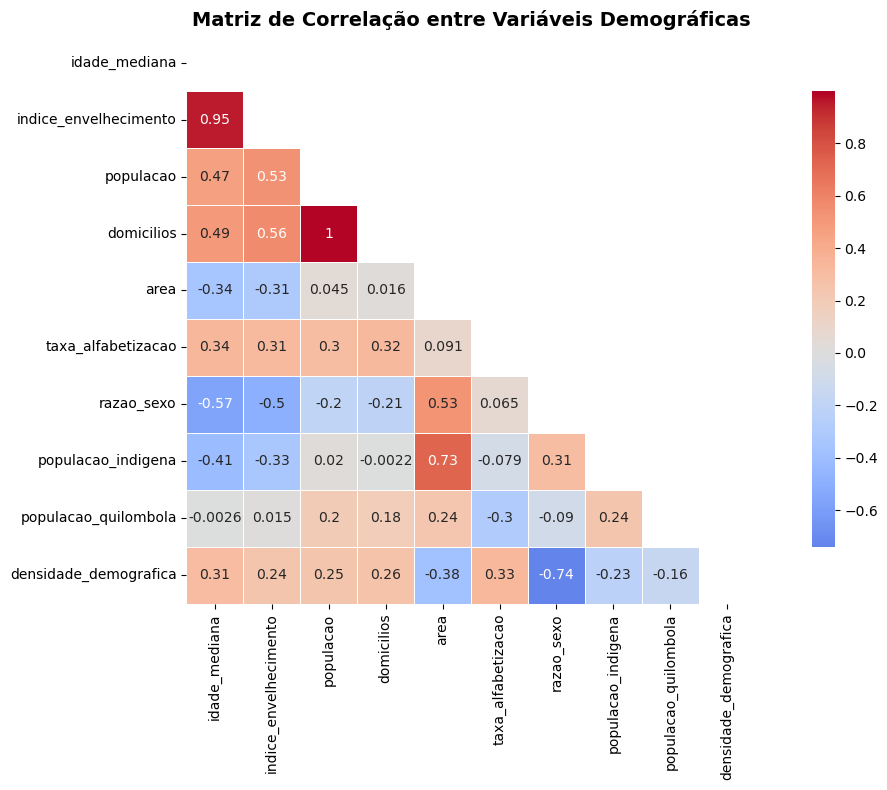

In [18]:
#GRÁFICO ADICIONAL: HEATMAP DE CORRELAÇÃO

plt.figure(figsize=(12, 8))
correlacao = df_completo[colunas_disponiveis].corr()

mask = np.triu(np.ones_like(correlacao, dtype=bool))

import seaborn as sns
sns.heatmap(correlacao, mask=mask, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": .8})
plt.title('Matriz de Correlação entre Variáveis Demográficas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../resultados/correlacao_variaveis.png', dpi=300, bbox_inches='tight')
plt.show()